In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path("../src").resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from plotnine import (ggplot, 
                      aes, 
                      geom_col, 
                      coord_flip, 
                      labs, theme, 
                      theme_minimal,
                      element_rect, 
                      element_line, 
                      element_text, 
                      element_blank)


DATA_DIR = Path("../data")
PROCESSED_DIR = DATA_DIR / "processed"
FIGURES_DIR = Path("../figures")


from summaries import summarize_group

In [2]:
Express_df = pd.read_csv(PROCESSED_DIR / "ExpressMart_processed.csv", parse_dates=["order_datetime"])


In [3]:
Express_df.shape

(185652, 12)

In [4]:
Express_df.head()

,order_id,product,quantity_ordered,price_each,purchase_address,sales,order_datetime,month,hour,city,state,city_state
0,295665,Macbook Pro Laptop,1,1700.00,"136 Church St, New York City, NY 10001",1700.00,2019-12-30 00:01:00,12,0,New York City,NY,"New York City, NY"
1,295666,LG Washing Machine,1,600.00,"562 2nd St, New York City, NY 10001",600.00,2019-12-29 07:03:00,12,7,New York City,NY,"New York City, NY"
2,295667,USB-C Charging Cable,1,11.95,"277 Main St, New York City, NY 10001",11.95,2019-12-12 18:21:00,12,18,New York City,NY,"New York City, NY"
3,295668,27in FHD Monitor,1,149.99,"410 6th St, San Francisco, CA 94016",149.99,2019-12-22 15:13:00,12,15,San Francisco,CA,"San Francisco, CA"
4,295669,USB-C Charging Cable,1,11.95,"43 Hill St, Atlanta, GA 30301",11.95,2019-12-18 12:38:00,12,12,Atlanta,GA,"Atlanta, GA"


Distribution Plot

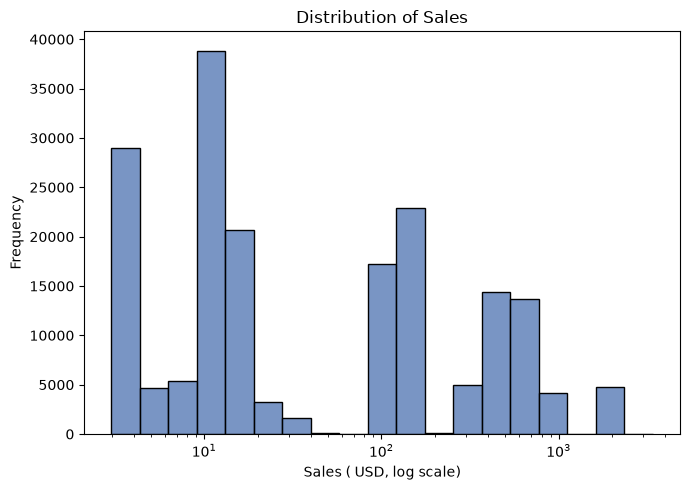

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.histplot(data= Express_df, x="sales", bins=19, log_scale=True,color = "#4C72B0", ax=ax)
ax.set(
    title = "Distribution of Sales",
    xlabel = "Sales ( USD, log scale)",
    ylabel = "Frequency")

fig.tight_layout()
plt.show()
fig.savefig(FIGURES_DIR / "sales_distribution.png", dpi=300, bbox_inches="tight")

**Figure 1.** Distribution of `sales` per purchase in 2019, with the x-axis on a log scale (the data itself is unchanged). Most purchases are small, with separate clusters for cheap accessories, mid-priced items and expensive electronics. This is why the median purchase ($14.95) is far below the mean ($185.60). The distribution of the data is very skewed to the right.

In [6]:
by_city = summarize_group(Express_df, "city_state")
by_city["revenue_m"] = by_city["total_sales"] / 1000000
by_city[["city_state", "revenue_m"]]

,city_state,revenue_m
0,"San Francisco, CA",8.252259
1,"Los Angeles, CA",5.447304
2,"New York City, NY",4.660527
3,"Boston, MA",3.657301
4,"Atlanta, GA",2.794199
5,"Dallas, TX",2.763659
6,"Seattle, WA",2.744896
7,"Portland, OR",1.869858
8,"Austin, TX",1.817544
9,"Portland, ME",0.449321


In [7]:
by_city["city_state"] = pd.Categorical(
    by_city["city_state"],
    categories=by_city["city_state"][::-1],
    ordered=True,
)

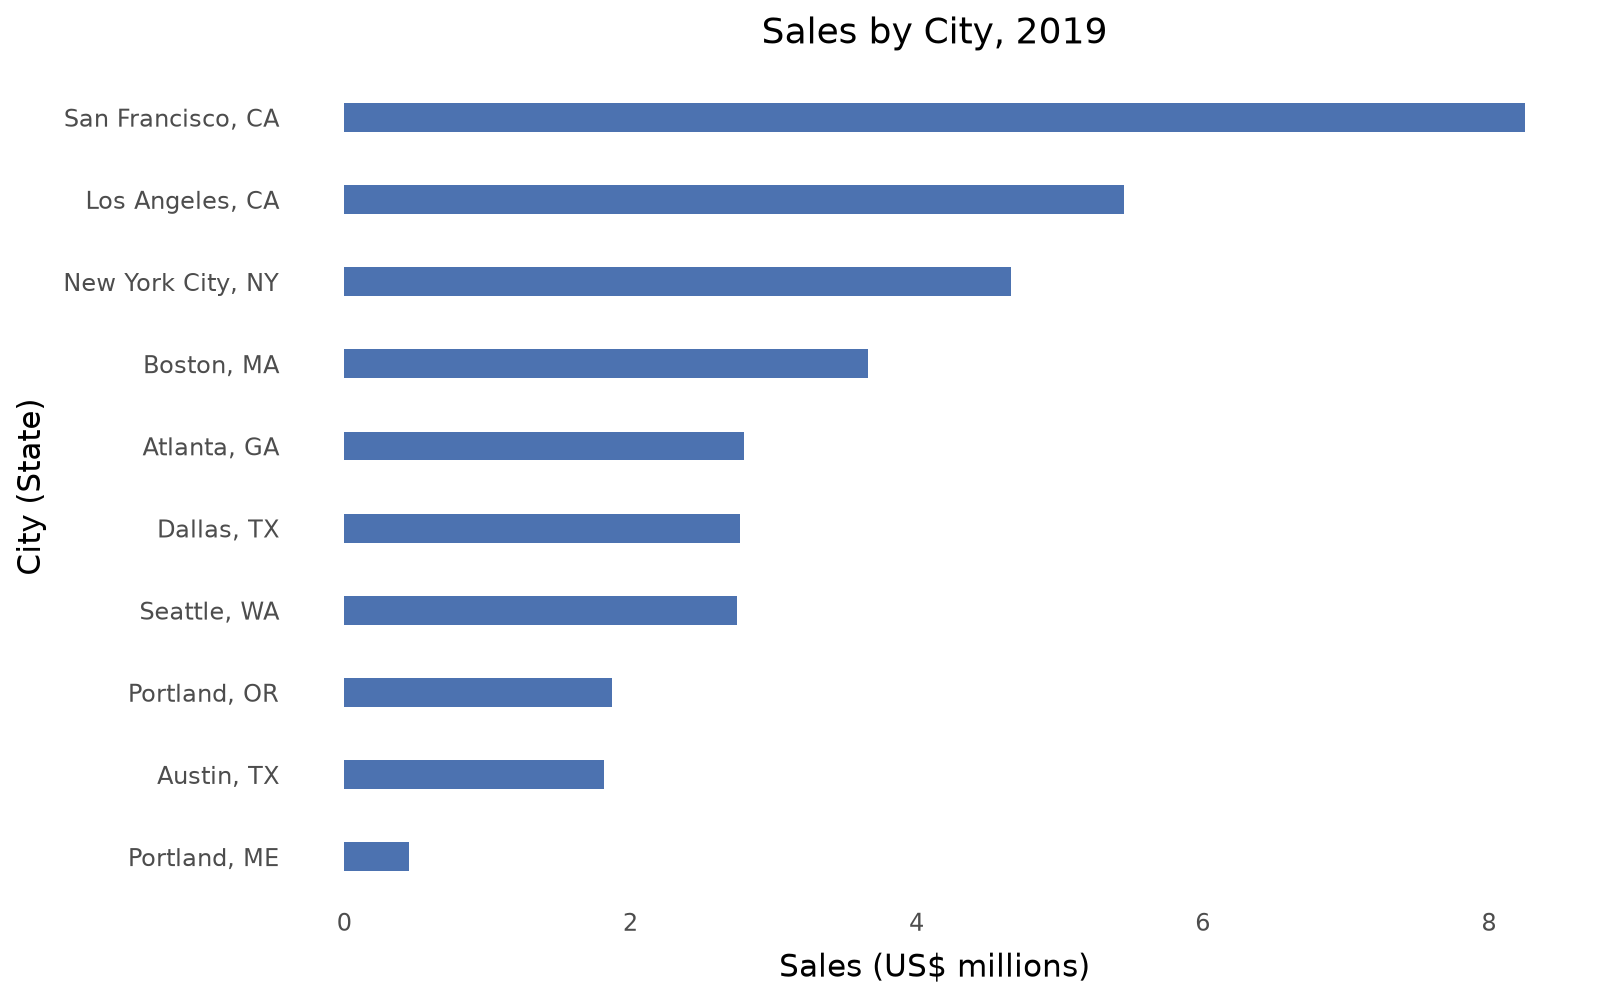

In [8]:
p = (
    ggplot(by_city, aes(x="city_state", y="revenue_m"))
    + geom_col(fill="#4C72B0", width=0.35)
    + coord_flip()
    + labs(title="Sales by City, 2019", x="City (State)", y="Sales (US$ millions)")
    + theme_minimal()
    + theme(
        figure_size=(8, 5),
        plot_background=element_rect(fill="white", color="white"),
        panel_background=element_rect(fill="white"),
        panel_grid=element_blank(),
        plot_title=element_text(size=13, ha="center"),
    )
)

p.save(FIGURES_DIR / "revenue_by_city.png", dpi=300, verbose=False)
p


**Figure 2.** `total_sales` by city in 2019, in US$ millions. San Francisco is the largest by a wide margin and Portland, ME is the smallest. San Francisco has the highest `total_sales` at about $8.25 million, which is 23.9% of all sales. Los Angeles ($5.45M, 15.8%) and New York City ($4.66M, 13.5%) follow. Portland, ME is the lowest at about $0.45 million (0.013), so San Francisco earns roughly 18 times as much.


In [9]:
by_hour = summarize_group(Express_df, "hour").sort_values("hour").reset_index(drop=True)
by_hour[["hour", "quantity_sold"]].head()

,hour,quantity_sold
0,0,4404
1,1,2607
2,2,1393
3,3,921
4,4,931


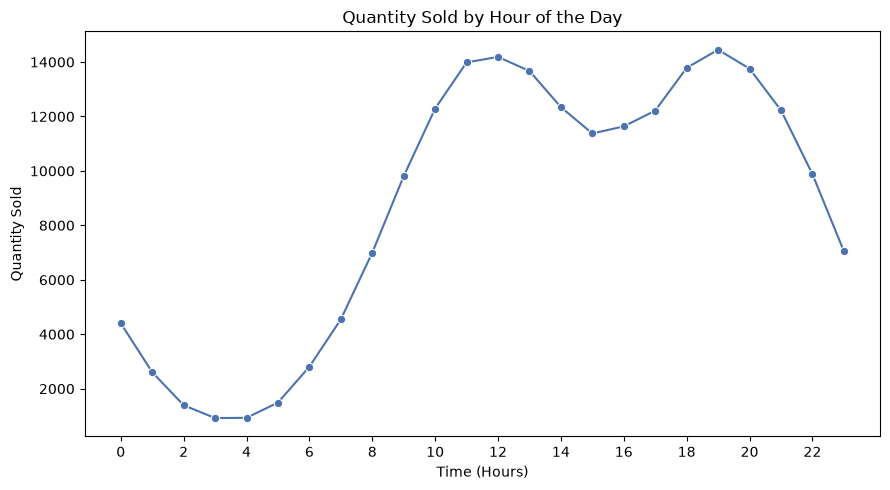

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=by_hour, x="hour", y="quantity_sold", marker="o",color = "#4C72B0", ax=ax)
ax.set_xticks(range(0, 24, 2))

ax.set_title("Quantity Sold by Hour of the Day")
ax.set_xlabel("Time (Hours)")
ax.set_ylabel("Quantity Sold")


fig.tight_layout()
fig.savefig(FIGURES_DIR / "orders_by_hour.png", dpi=300, bbox_inches="tight")
plt.show()

**Figure 3.** Quantity sold in each hour of the day, 2019 total. Sales peak around noon and 7 pm, dip in the afternoon, and are lowest around 3 am. 

Orders show two clear sales peaks throughout the day. The first occurs at noon, with 14,188 units sold and total sales of $2,314,359.85. The second and highest peak occurs at 7 PM, with 14,451 units sold and total sales of $2,411,971.14. Between these peaks, sales experience an afternoon dip, reaching their lowest point at 3 PM, approximately 19% below the noon peak. The quietest time of the day is 3 AM, when only 921 units are sold.

In [11]:
by_product = Express_df.groupby("product").agg(
    price=("price_each", "mean"),
    units=("quantity_ordered", "sum"),
).reset_index()


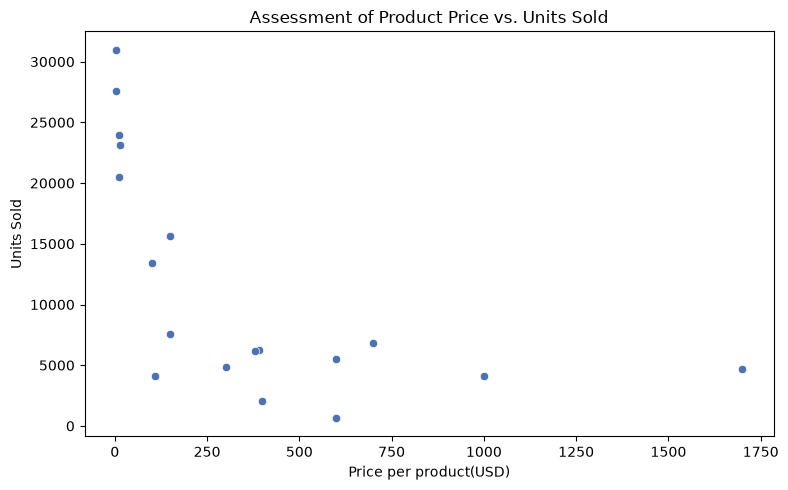

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=by_product, x="price", y="units", color ="#4C72B0", ax=ax)

ax.set_title("Assessment of Product Price vs. Units Sold")
ax.set_xlabel("Price per product(USD)")
ax.set_ylabel("Units Sold")


fig.tight_layout()
fig.savefig(FIGURES_DIR / "price_vs_units.png", dpi=300, bbox_inches="tight")
plt.show()

**Figure 4.** `price_each` against `quantity_sold` for each of the 19 products. Cheaper products tend to have a higher quantity sold (correlation about -0.60), but some products, such as Apple AirPods Headphones, sell more than their price would suggest.

In [13]:
by_product_full = summarize_group(Express_df, "product")
by_product_full[["product", "quantity_sold", "total_sales"]].head()

,product,quantity_sold,total_sales
0,Macbook Pro Laptop,4724,8030800.00
1,iPhone,6845,4791500.00
2,ThinkPad Laptop,4126,4125958.74
3,Google Phone,5528,3316800.00
4,27in 4K Gaming Monitor,6238,2432757.62


In [14]:
by_product_full.sort_values("quantity_sold", ascending=False)[["product", "quantity_sold", "total_sales"]].head(5)

,product,quantity_sold,total_sales
18,AAA Batteries (4-pack),30981,92633.19
17,AA Batteries (4-pack),27615,106041.60
15,USB-C Charging Cable,23927,285927.65
14,Lightning Charging Cable,23163,346286.85
16,Wired Headphones,20520,246034.80


In [15]:
top_units = by_product_full.nlargest(5, "quantity_sold")
top_revenue = by_product_full.nlargest(5, "total_sales").copy()
top_revenue["revenue_m"] = top_revenue["total_sales"] / 1000000

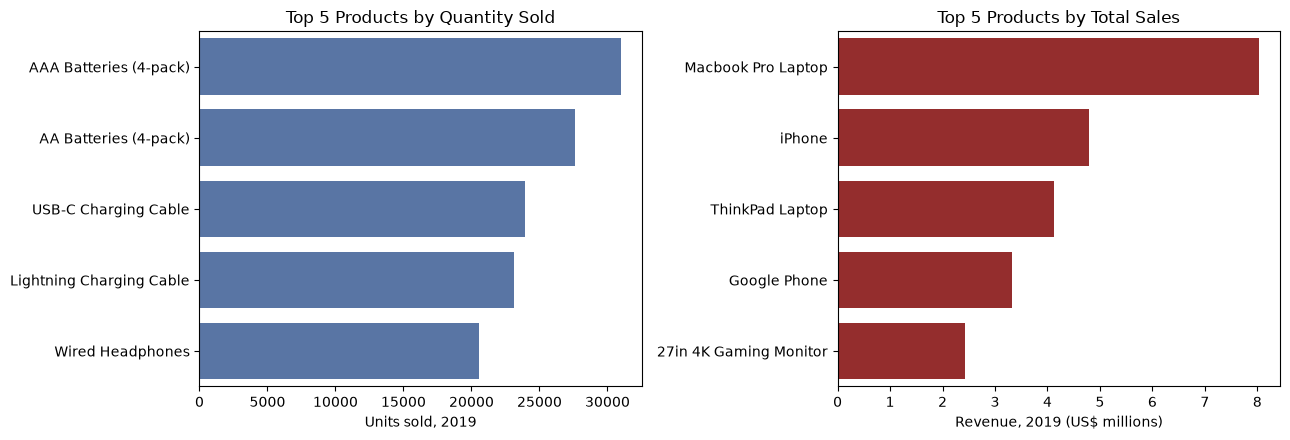

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(data=top_units, x="quantity_sold", y="product", color="#4C72B0", ax=axes[0])
axes[0].set_title("Top 5 Products by Quantity Sold")
axes[0].set_xlabel("Units sold, 2019")
axes[0].set_ylabel("")

sns.barplot(data=top_revenue, x="revenue_m", y="product", color="#A51C1C", ax=axes[1])
axes[1].set_title("Top 5 Products by Total Sales")
axes[1].set_xlabel("Revenue, 2019 (US$ millions)")
axes[1].set_ylabel("")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "top_products.png", dpi=300, bbox_inches="tight")
plt.show()

**Figure 5.** The five products with the highest `quantity_sold` (left) and the five with the highest `total_sales` (right). The two lists share no products: cheap accessories sell the most items, while laptops, phones and a gaming monitor bring in the most money.